In [1]:
import os

for folder in ["/content/src", "/content/hasil",
               "/content/data/data/sintetis"]:
    print(folder, ":", os.path.exists(folder))

/content/src : False
/content/hasil : False
/content/data/data/sintetis : False


In [2]:
import os

print("Isi folder /content:")
print(os.listdir("/content"))

Isi folder /content:
['.config', 'sample_data']


In [3]:
from google.colab import files

uploaded = files.upload()

Saving dataset_simuteh.zip to dataset_simuteh.zip


In [4]:
import os

file_zip = [f for f in os.listdir("/content") if f.endswith(".zip")]
print("File ZIP:", file_zip)

File ZIP: ['dataset_simuteh.zip']


In [5]:
import zipfile
import os

nama_zip = file_zip[0]
with zipfile.ZipFile("/content/" + nama_zip, "r") as zip_ref:
    zip_ref.extractall("/content/data")

print("Dataset berhasil diekstrak!")
print("Isi folder data:", os.listdir("/content/data"))

Dataset berhasil diekstrak!
Isi folder data: ['data']


In [6]:
import os

for root, dirs, files in os.walk("/content/data"):
    level = root.replace("/content/data", "").count(os.sep)
    indent = " " * 4 * level
    print(f"{indent}{os.path.basename(root)}/")
    for file in files[:5]:
        print(f"{indent}    {file}")

data/
    data/
        sintetis/
            label.csv
            citra/
                teh_056.png
                teh_027.png
                teh_035.png
                teh_055.png
                teh_031.png
            mask_bercak/
                teh_056.png
                teh_027.png
                teh_035.png
                teh_055.png
                teh_031.png
            bersih/
                teh_056.png
                teh_027.png
                teh_035.png
                teh_055.png
                teh_031.png
            mask_daun/
                teh_056.png
                teh_027.png
                teh_035.png
                teh_055.png
                teh_031.png


In [7]:
import os

os.makedirs("/content/src", exist_ok=True)
os.makedirs("/content/hasil", exist_ok=True)

print("Folder src dan hasil berhasil dibuat!")
print("Folder src:", os.path.exists("/content/src"))
print("Folder hasil:", os.path.exists("/content/hasil"))

Folder src dan hasil berhasil dibuat!
Folder src: True
Folder hasil: True


In [8]:
%%writefile /content/src/praproses.py

import json
import os
import cv2
import numpy as np

PARAM_BAWAAN = {
    "lebar": 640,
    "gamma": 1.0,
    "clahe_clip": 2.0,
    "clahe_tile": 8,
    "penapis": "median",
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0,
}

def praproses(img_bgr, p=None):
    p = {**PARAM_BAWAAN, **(p or {})}

    if img_bgr is None:
        raise ValueError("Citra tidak boleh kosong.")

    img = img_bgr.copy()

    # 1. Resize
    tinggi, lebar = img.shape[:2]
    skala = p["lebar"] / lebar
    tinggi_baru = max(1, round(tinggi * skala))

    img = cv2.resize(
        img,
        (p["lebar"], tinggi_baru),
        interpolation=cv2.INTER_AREA
    )

    # 2. Gamma correction
    if p["gamma"] != 1:
        tabel = np.array([
            ((i / 255.0) ** (1.0 / p["gamma"])) * 255
            for i in range(256)
        ]).clip(0, 255).astype("uint8")

        img = cv2.LUT(img, tabel)

    # 3. CLAHE pada channel V HSV
    if p["clahe_clip"] > 0:
        hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)

        clahe = cv2.createCLAHE(
            clipLimit=p["clahe_clip"],
            tileGridSize=(p["clahe_tile"], p["clahe_tile"])
        )

        hsv[:, :, 2] = clahe.apply(hsv[:, :, 2])
        img = cv2.cvtColor(hsv, cv2.COLOR_HSV2BGR)

    # 4. Denoising
    penapis = p["penapis"].lower()
    kernel = int(p["kernel"])

    if penapis != "none":
        if kernel < 3 or kernel % 2 == 0:
            raise ValueError("Kernel harus ganjil dan minimal 3.")

        if penapis == "rerata":
            img = cv2.blur(img, (kernel, kernel))

        elif penapis == "gaussian":
            img = cv2.GaussianBlur(
                img, (kernel, kernel), p["sigma"]
            )

        elif penapis == "median":
            img = cv2.medianBlur(img, kernel)

        else:
            raise ValueError("Jenis penapis tidak dikenal.")

    # 5. Unsharp masking
    if p["tajam_k"] > 0:
        blur = cv2.GaussianBlur(img, (0, 0), 1.0)

        img = cv2.addWeighted(
            img, 1.0 + p["tajam_k"],
            blur, -p["tajam_k"],
            0
        )

    return img


def simpan_param(p, path="../hasil/param_praproses.json"):
    folder = os.path.dirname(path)

    if folder:
        os.makedirs(folder, exist_ok=True)

    param_final = {**PARAM_BAWAAN, **p}

    with open(path, "w") as f:
        json.dump(param_final, f, indent=2)

    print("Parameter berhasil disimpan:", path)

Writing /content/src/praproses.py


In [9]:
import sys

sys.path.insert(0, "/content/src")

from praproses import praproses, simpan_param

print("Modul praproses berhasil diimpor!")

Modul praproses berhasil diimpor!


Citra berhasil dibaca: True
Ukuran citra awal: (480, 640, 3)
Ukuran hasil praproses: (480, 640, 3)


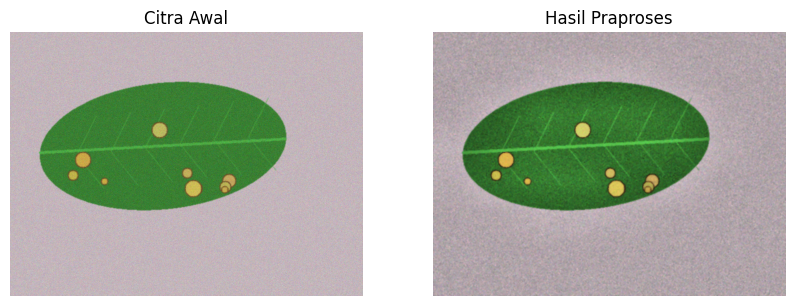

In [10]:
import cv2
import matplotlib.pyplot as plt

path_uji = "/content/data/data/sintetis/citra/teh_056.png"

img_uji = cv2.imread(path_uji)

print("Citra berhasil dibaca:", img_uji is not None)
print("Ukuran citra awal:", img_uji.shape)

hasil_uji = praproses(img_uji)

print("Ukuran hasil praproses:", hasil_uji.shape)

# Tampilkan perbandingan
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
plt.imshow(cv2.cvtColor(img_uji, cv2.COLOR_BGR2RGB))
plt.title("Citra Awal")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(cv2.cvtColor(hasil_uji, cv2.COLOR_BGR2RGB))
plt.title("Hasil Praproses")
plt.axis("off")

plt.show()

In [11]:
import pandas as pd

path_csv = "/content/data/data/sintetis/label.csv"
df = pd.read_csv(path_csv)

print("5 data pertama:")
display(df.head())

print("\nJumlah data per kelas:")
display(df["kelas"].value_counts())

print("\nJumlah data per kondisi cahaya:")
display(df["kondisi_cahaya"].value_counts())

5 data pertama:


,nama_file,kelas,kondisi_cahaya,persen_bercak
0,teh_001.png,sehat,normal,0.0
1,teh_002.png,sehat,gelap,0.0
2,teh_003.png,sehat,terang,0.0
3,teh_004.png,sehat,kontras_rendah,0.0
4,teh_005.png,sehat,bayangan,0.0



Jumlah data per kelas:


,count
kelas,
sehat,20
ringan,20
berat,20



Jumlah data per kondisi cahaya:


,count
kondisi_cahaya,
normal,12
gelap,12
terang,12
kontras_rendah,12
bayangan,12


In [12]:
import cv2
import numpy as np
import pandas as pd
import os

BASE = "/content/data/data/sintetis"

hasil_kanal = []

for _, row in df[df["kelas"].isin(["ringan", "berat"])].iterrows():
    nama = row["nama_file"]

    img = cv2.imread(os.path.join(BASE, "citra", nama))
    md = cv2.imread(os.path.join(BASE, "mask_daun", nama), 0)
    mb = cv2.imread(os.path.join(BASE, "mask_bercak", nama), 0)

    if img is None or md is None or mb is None:
        continue

    daun = md > 0
    bercak = mb > 0
    daun_normal = daun & (~bercak)

    for kanal, nama_kanal in enumerate(["B", "G", "R"]):
        nilai_bercak = img[:, :, kanal][bercak]
        nilai_daun = img[:, :, kanal][daun_normal]

        if len(nilai_bercak) == 0 or len(nilai_daun) == 0:
            continue

        kb = abs(
            np.mean(nilai_bercak) - np.mean(nilai_daun)
        )

        hasil_kanal.append({
            "nama_file": nama,
            "kondisi_cahaya": row["kondisi_cahaya"],
            "kanal": nama_kanal,
            "KB": kb
        })

df_kanal = pd.DataFrame(hasil_kanal)

ringkasan_kanal = (
    df_kanal.groupby("kanal")["KB"]
    .mean()
    .sort_values(ascending=False)
)

print("Rata-rata indikator kontras setiap kanal:")
display(ringkasan_kanal)

KANAL = {"B": 0, "G": 1, "R": 2}[ringkasan_kanal.index[0]]

print("Kanal terbaik sementara:", ringkasan_kanal.index[0])
print("Indeks kanal:", KANAL)

Rata-rata indikator kontras setiap kanal:


,KB
kanal,
R,72.324468
B,13.641181
G,10.299543


Kanal terbaik sementara: R
Indeks kanal: 2


In [13]:
PARAM_UJI = {
    "lebar": 640,
    "gamma": 1.0,
    "clahe_clip": 2.0,
    "clahe_tile": 8,
    "penapis": "median",
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0,
}

In [14]:
simpan_param(
    PARAM_UJI,
    "/content/hasil/param_praproses.json"
)

print("Parameter awal berhasil disimpan!")

Parameter berhasil disimpan: /content/hasil/param_praproses.json
Parameter awal berhasil disimpan!


In [15]:
import os
import cv2
import numpy as np
import pandas as pd

BASE = "/content/data/data/sintetis"

def kontras_bercak(channel, md, mb):
    """
    KB = selisih rata-rata intensitas bercak
    dengan area daun yang tidak bercak.
    """
    daun = md > 0
    bercak = mb > 0
    daun_normal = daun & (~bercak)

    if not np.any(bercak) or not np.any(daun_normal):
        return np.nan

    mean_bercak = np.mean(channel[bercak])
    mean_daun = np.mean(channel[daun_normal])

    return abs(mean_bercak - mean_daun)


data_kb = []

for _, row in df[df["kelas"].isin(["ringan", "berat"])].iterrows():

    nama = row["nama_file"]

    img = cv2.imread(os.path.join(BASE, "citra", nama))
    md = cv2.imread(os.path.join(BASE, "mask_daun", nama), 0)
    mb = cv2.imread(os.path.join(BASE, "mask_bercak", nama), 0)

    if img is None or md is None or mb is None:
        print("File tidak ditemukan:", nama)
        continue

    # KB sebelum praproses
    kb_sebelum = kontras_bercak(img[:, :, KANAL], md, mb)

    # Praproses
    img_after = praproses(img, PARAM_UJI)

    # Sesuaikan ukuran mask jika ukuran citra berubah
    ukuran = (img_after.shape[1], img_after.shape[0])
    md_after = cv2.resize(md, ukuran, interpolation=cv2.INTER_NEAREST)
    mb_after = cv2.resize(mb, ukuran, interpolation=cv2.INTER_NEAREST)

    # KB sesudah praproses
    kb_sesudah = kontras_bercak(
        img_after[:, :, KANAL],
        md_after,
        mb_after
    )

    data_kb.append({
        "nama_file": nama,
        "kelas": row["kelas"],
        "kondisi_cahaya": row["kondisi_cahaya"],
        "KB_sebelum": kb_sebelum,
        "KB_sesudah": kb_sesudah
    })

df_kb = pd.DataFrame(data_kb)

print("Jumlah citra berhasil diuji:", len(df_kb))
display(df_kb.head())

Jumlah citra berhasil diuji: 40


,nama_file,kelas,kondisi_cahaya,KB_sebelum,KB_sesudah
0,teh_021.png,ringan,normal,86.192297,70.716116
1,teh_022.png,ringan,gelap,72.668585,81.576588
2,teh_023.png,ringan,terang,60.109273,61.642936
3,teh_024.png,ringan,kontras_rendah,31.781021,43.377432
4,teh_025.png,ringan,bayangan,47.682083,72.312008


In [16]:
tabel12 = (
    df_kb.groupby("kondisi_cahaya")
    .agg(
        KB_sebelum=("KB_sebelum", "mean"),
        KB_sesudah=("KB_sesudah", "mean")
    )
    .reset_index()
)

tabel12["Perubahan (%)"] = np.where(
    tabel12["KB_sebelum"] != 0,
    (
        (tabel12["KB_sesudah"] - tabel12["KB_sebelum"])
        / tabel12["KB_sebelum"]
    ) * 100,
    np.nan
)

tabel12["Keterangan"] = np.where(
    tabel12["Perubahan (%)"] > 0,
    "Kontras meningkat",
    np.where(
        tabel12["Perubahan (%)"] < 0,
        "Kontras menurun",
        "Tidak berubah"
    )
)

display(tabel12.round(2))

,kondisi_cahaya,KB_sebelum,KB_sesudah,Perubahan (%),Keterangan
0,bayangan,62.97,79.28,25.91,Kontras meningkat
1,gelap,93.57,107.32,14.70,Kontras meningkat
2,kontras_rendah,34.76,46.39,33.45,Kontras meningkat
3,normal,98.16,100.76,2.64,Kontras meningkat
4,terang,72.16,68.34,-5.29,Kontras menurun


In [17]:
hasil_sehat = []

for _, row in df[df["kelas"] == "sehat"].iterrows():

    nama = row["nama_file"]

    img = cv2.imread(os.path.join(BASE, "citra", nama))
    md = cv2.imread(os.path.join(BASE, "mask_daun", nama), 0)

    if img is None or md is None:
        print("File tidak ditemukan:", nama)
        continue

    # Sebelum praproses
    std_sebelum = np.std(img[:, :, KANAL][md > 0])

    # Sesudah praproses
    img_after = praproses(img, PARAM_UJI)

    md_after = cv2.resize(
        md,
        (img_after.shape[1], img_after.shape[0]),
        interpolation=cv2.INTER_NEAREST
    )

    std_sesudah = np.std(img_after[:, :, KANAL][md_after > 0])

    hasil_sehat.append({
        "nama_file": nama,
        "kondisi_cahaya": row["kondisi_cahaya"],
        "STD_sebelum": std_sebelum,
        "STD_sesudah": std_sesudah
    })

df_sehat = pd.DataFrame(hasil_sehat)

print("Jumlah citra sehat diuji:", len(df_sehat))
display(df_sehat.head())

Jumlah citra sehat diuji: 20


,nama_file,kondisi_cahaya,STD_sebelum,STD_sesudah
0,teh_001.png,normal,11.285003,10.954056
1,teh_002.png,gelap,8.118045,5.280415
2,teh_003.png,terang,9.066760,10.971103
3,teh_004.png,kontras_rendah,12.399707,11.526608
4,teh_005.png,bayangan,12.138004,8.043061


In [18]:
tabel_sehat = (
    df_sehat.groupby("kondisi_cahaya")
    .agg(
        STD_sebelum=("STD_sebelum", "mean"),
        STD_sesudah=("STD_sesudah", "mean")
    )
    .reset_index()
)

tabel_sehat["Perubahan (%)"] = (
    (tabel_sehat["STD_sesudah"] - tabel_sehat["STD_sebelum"])
    / tabel_sehat["STD_sebelum"]
) * 100

display(tabel_sehat.round(2))

,kondisi_cahaya,STD_sebelum,STD_sesudah,Perubahan (%)
0,bayangan,14.29,9.54,-33.20
1,gelap,9.94,6.57,-33.84
2,kontras_rendah,10.23,9.75,-4.69
3,normal,12.55,10.07,-19.74
4,terang,9.42,11.71,24.23


In [19]:
import matplotlib.pyplot as plt

kondisi_list = [
    "normal",
    "gelap",
    "terang",
    "kontras_rendah",
    "bayangan"
]

fig, axes = plt.subplots(5, 2, figsize=(10, 20))

for i, kondisi in enumerate(kondisi_list):

    sampel = df_sehat[
        df_sehat["kondisi_cahaya"] == kondisi
    ].iloc[0]

    nama = sampel["nama_file"]

    img = cv2.imread(
        os.path.join(BASE, "citra", nama)
    )

    img_after = praproses(img, PARAM_UJI)

    axes[i, 0].imshow(
        cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    )
    axes[i, 0].set_title(f"{kondisi} - Sebelum")

    axes[i, 1].imshow(
        cv2.cvtColor(img_after, cv2.COLOR_BGR2RGB)
    )
    axes[i, 1].set_title(f"{kondisi} - Sesudah")

    axes[i, 0].axis("off")
    axes[i, 1].axis("off")

plt.tight_layout()
plt.show()

Output hidden; open in https://colab.research.google.com to view.

In [20]:
PARAM_FINAL = {
    "lebar": 640,
    "gamma": 1.0,
    "clahe_clip": 2.0,
    "clahe_tile": 8,
    "penapis": "median",
    "kernel": 3,
    "sigma": 1.0,
    "tajam_k": 0.0,
}

simpan_param(
    PARAM_FINAL,
    "/content/hasil/param_praproses.json"
)

print("Isi parameter final:")
display(PARAM_FINAL)

print("\nFile berhasil disimpan:",
      os.path.exists("/content/hasil/param_praproses.json"))

Parameter berhasil disimpan: /content/hasil/param_praproses.json
Isi parameter final:


{'lebar': 640,
 'gamma': 1.0,
 'clahe_clip': 2.0,
 'clahe_tile': 8,
 'penapis': 'median',
 'kernel': 3,
 'sigma': 1.0,
 'tajam_k': 0.0}


File berhasil disimpan: True


In [21]:
import os

print("Isi folder src:", os.listdir("/content/src"))
print("Isi folder hasil:", os.listdir("/content/hasil"))

Isi folder src: ['praproses.py', '__pycache__']
Isi folder hasil: ['param_praproses.json']
